In [2]:
import os
import tempfile
import scanpy as sc
import scvi
import seaborn as sns
import torch
from rich import print
from pytorch_lightning import Trainer
import numpy as np
from scvi.external import MRVI
import pandas as pd


In [57]:
scRNA_PTEN_path = "/Users/tobymilne-clark/Documents/Data/Atlas/scRNA_prostate/H5ad/External/5739e080-4dbc-48e2-91dd-feaa1d7ad773.h5ad"

adata = sc.read(filename=scRNA_PTEN_path)
adata

AnnData object with n_obs × n_vars = 68322 × 32397
    obs: 'donor_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_type', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'sample', 'type', 'ISUP_core', 'ISUP_clinical', 'pt_cancer', 'pt_normal', 'CNA_value.ck', 'cor.p.value.ck', 'cor.estimate.ck', 'pca_liu_up', 'pca_wallace_up', 'cancer_score', 'malignant_anno_merged', 'scn_major', 'celltype_major_v2', 'celltype_minor_v2', 'celltype_subset_v2', 'pca_setlur_erg_fusion_up', 'hallmark_androgen', 'is_primary_data', 'sample_id', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'gene_name', 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable', 'feature_is_filtered

In [58]:
sc.set_figure_params(figsize=(7, 7), frameon=False)
sns.set_theme()
torch.set_float32_matmul_precision("high")
save_dir = tempfile.TemporaryDirectory()

%config InlineBackend.print_figure_kwargs={"facecolor": "w"}
%config InlineBackend.figure_format="retina"

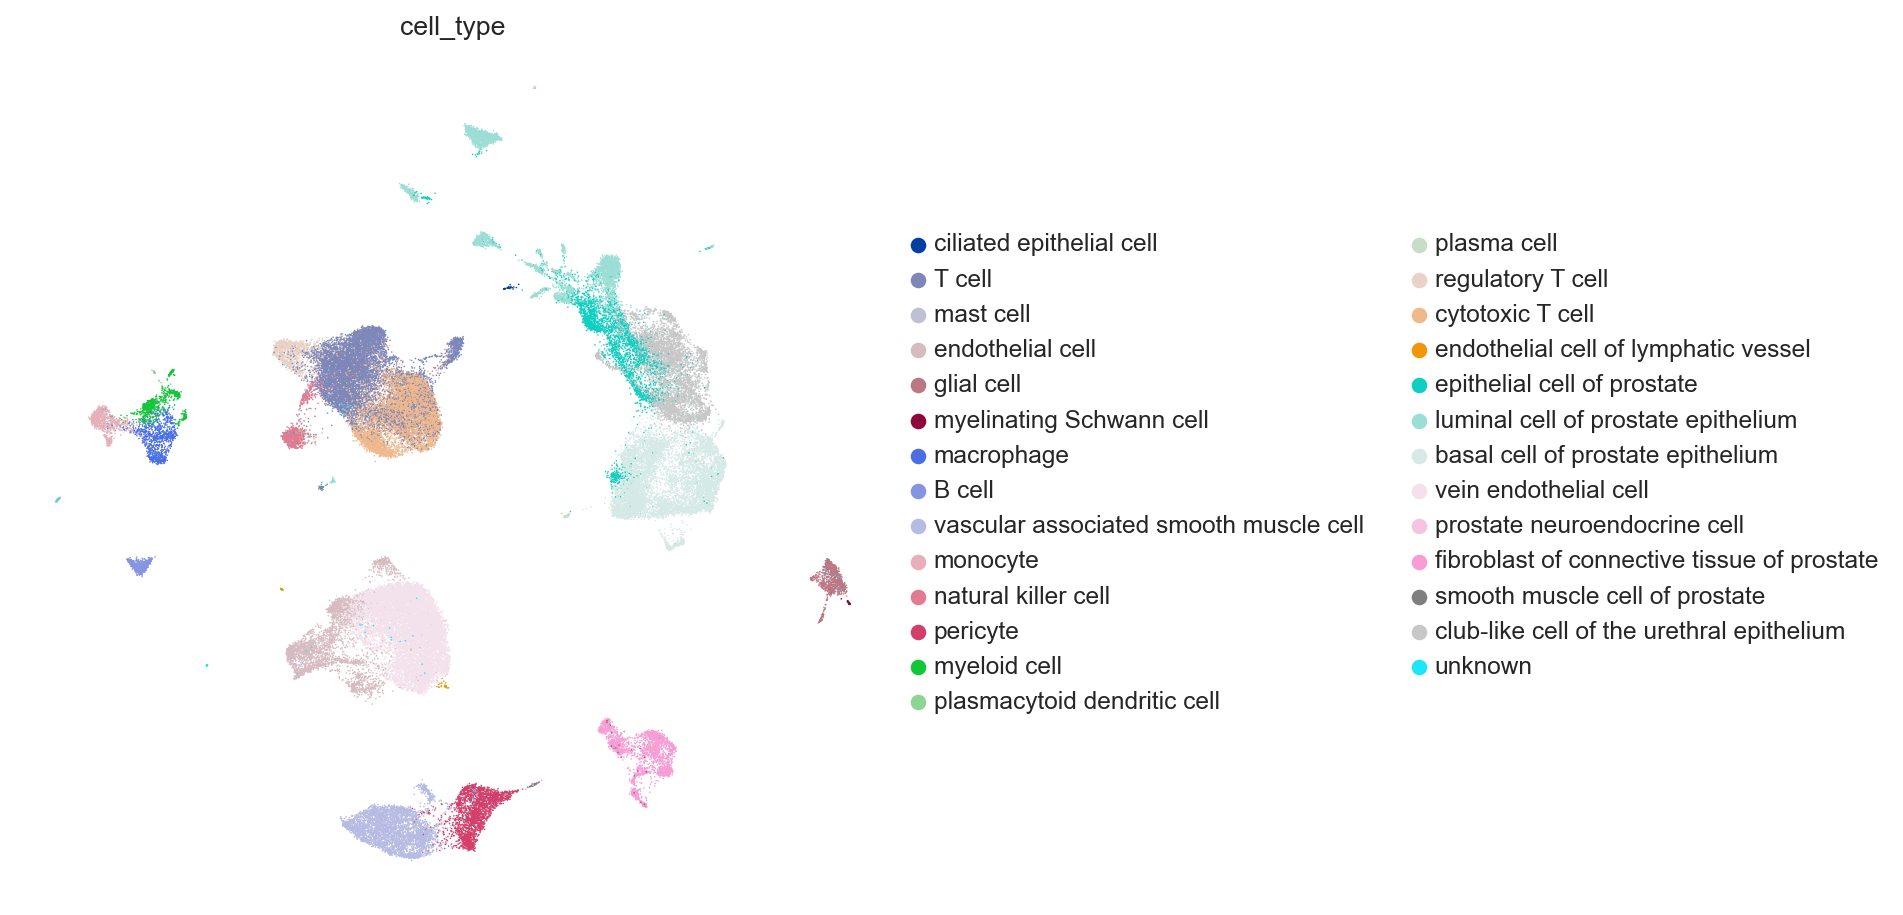

In [59]:
sc.pl.umap(
    adata,
    color="cell_type",     size=2,
)

In [104]:
plt.figure(figsize=(14, 7))
sc.pl.umap(
    adata,
    color=["cell_type"],
    size=2,
    show=False
)
plt.savefig("/Users/tobymilne-clark/Documents/Data/Atlas/scRNA_prostate/H5ad/External/plots/celltype_refined_umap.pdf", bbox_inches="tight", dpi=300)
plt.close()

<Figure size 1120x560 with 0 Axes>

In [103]:
plt.figure(figsize=(14, 7))
sc.pl.umap(
    adata,
    color=["celltype_major_v2", "cell_type"],
    size=2,
    show=False
)
plt.savefig("/Users/tobymilne-clark/Documents/Data/Atlas/scRNA_prostate/H5ad/External/plots/celltype_umap.pdf", bbox_inches="tight", dpi=300)
plt.close()

<Figure size 1120x560 with 0 Axes>

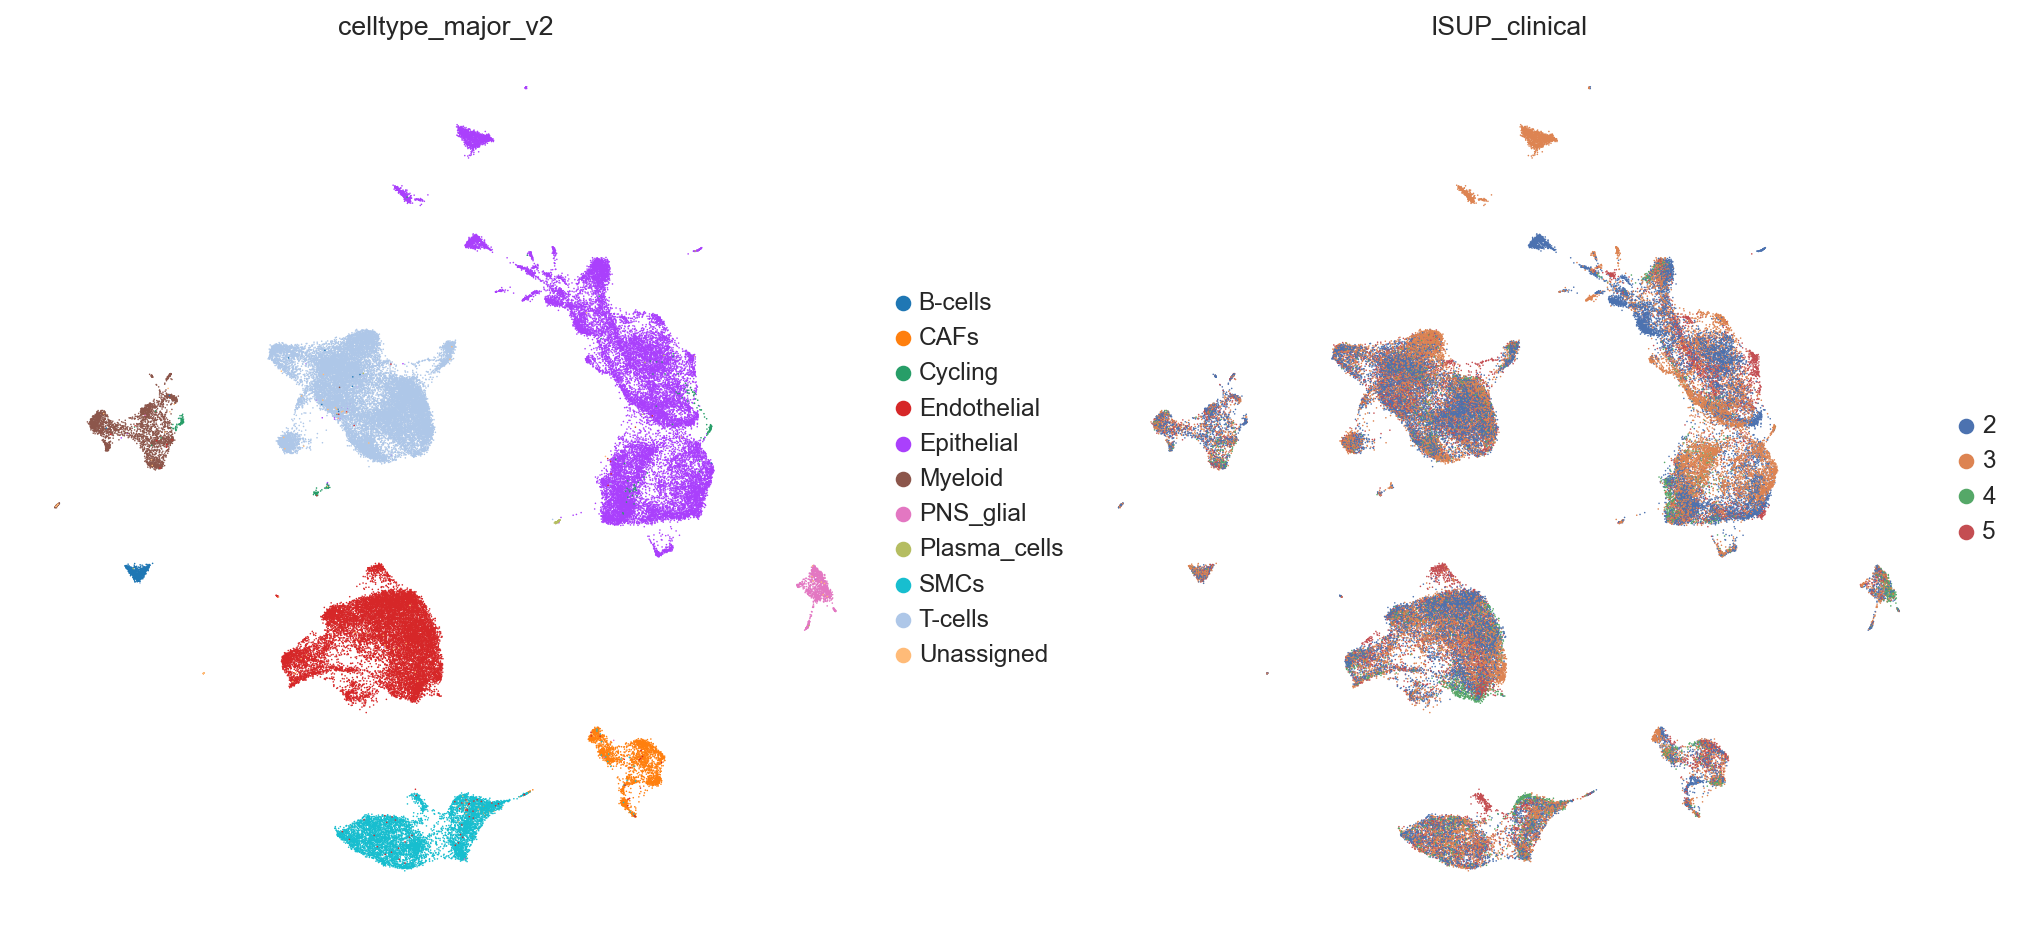

In [84]:
sc.pl.umap(
    adata,
    color=["celltype_major_v2","ISUP_clinical"],
    size=2,
)

In [67]:
def symbols_to_ensembl(gene_list, adata, symbol_col="gene_name", strip_version=False):
    df = adata.var.reset_index().rename(columns={"index": "ensembl_id"}).copy()
    
    if strip_version:
        df["ensembl_id"] = df["ensembl_id"].astype(str).str.split(".").str[0]
    
    df = df[[symbol_col, "ensembl_id"]].dropna()
    df[symbol_col] = df[symbol_col].astype(str)
    df["ensembl_id"] = df["ensembl_id"].astype(str)
    df = df.drop_duplicates(subset=[symbol_col])
    
    lookup = dict(zip(df[symbol_col], df["ensembl_id"]))
    mapped = {g: lookup.get(g) for g in gene_list}
    return mapped

In [77]:
neuronal_genes = ["NRXN1", "NRXN3", "NTRK3", "SLITRK3", "SLITRK4", "GRIN2D", "GRIA3", "SHANK2", "CAMK2A", "CAMK2B", "CAMKK2", "GABRA5", "GABRB1", "GABRG3", "SLC32A1", "SYT7", "ADCY1", "RASGRF1", "CHAT", "KIF17", "PPFIBP2"]
mapped = symbols_to_ensembl(neuronal_genes, adata, symbol_col="gene_name", strip_version=False)
gene_list_ens = [v for v in mapped.values() if v is not None]
gene_list_ens = [g for g in gene_list_ens if g in adata.var_names]

print(gene_list_ens)

sc.tl.score_genes(
    adata,
    gene_list=gene_list_ens,
    score_name="Neuronal_score"
)

[
    'ENSG00000179915',
    'ENSG00000021645',
    'ENSG00000140538',
    'ENSG00000121871',
    'ENSG00000179542',
    'ENSG00000105464',
    'ENSG00000125675',
    'ENSG00000162105',
    'ENSG00000070808',
    'ENSG00000058404',
    'ENSG00000110931',
    'ENSG00000186297',
    'ENSG00000163288',
    'ENSG00000182256',
    'ENSG00000101438',
    'ENSG00000011347',
    'ENSG00000164742',
    'ENSG00000058335',
    'ENSG00000117245',
    'ENSG00000166387'
]

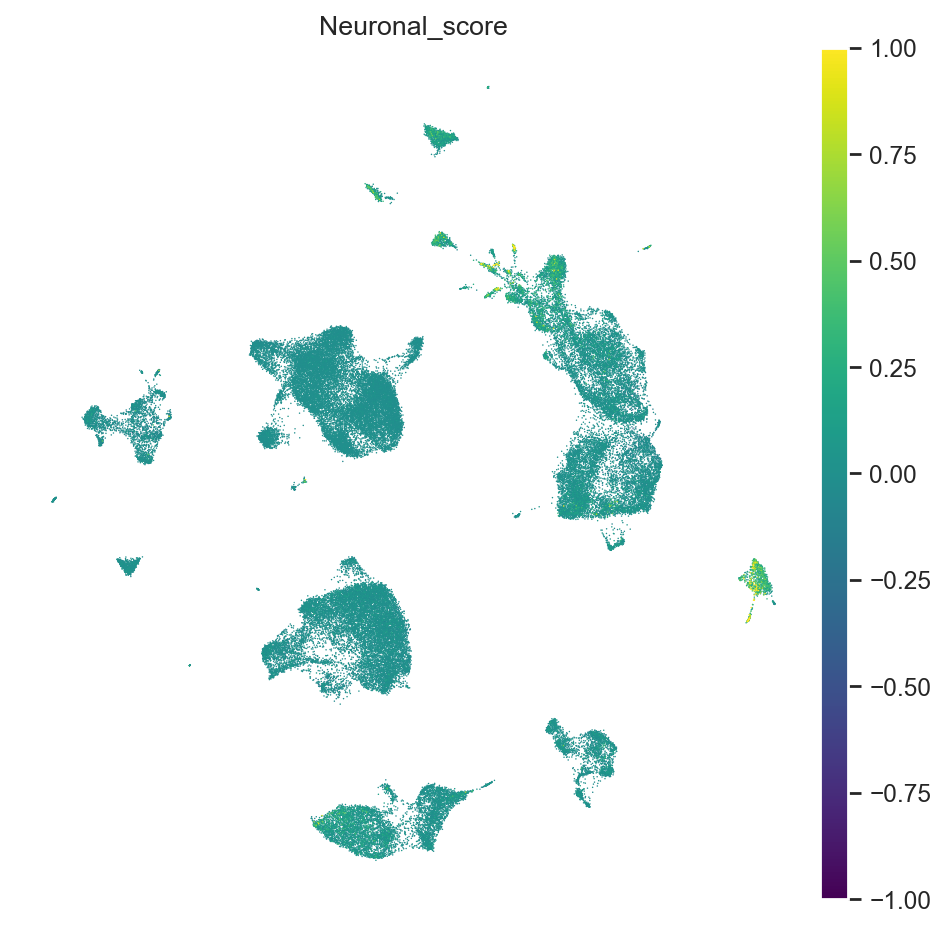

In [105]:
sc.pl.umap(
    adata,
    color=["Neuronal_score"],
    ncols=3,
    vmin=-1,
    vmax=1, 
    color_map="viridis",
)

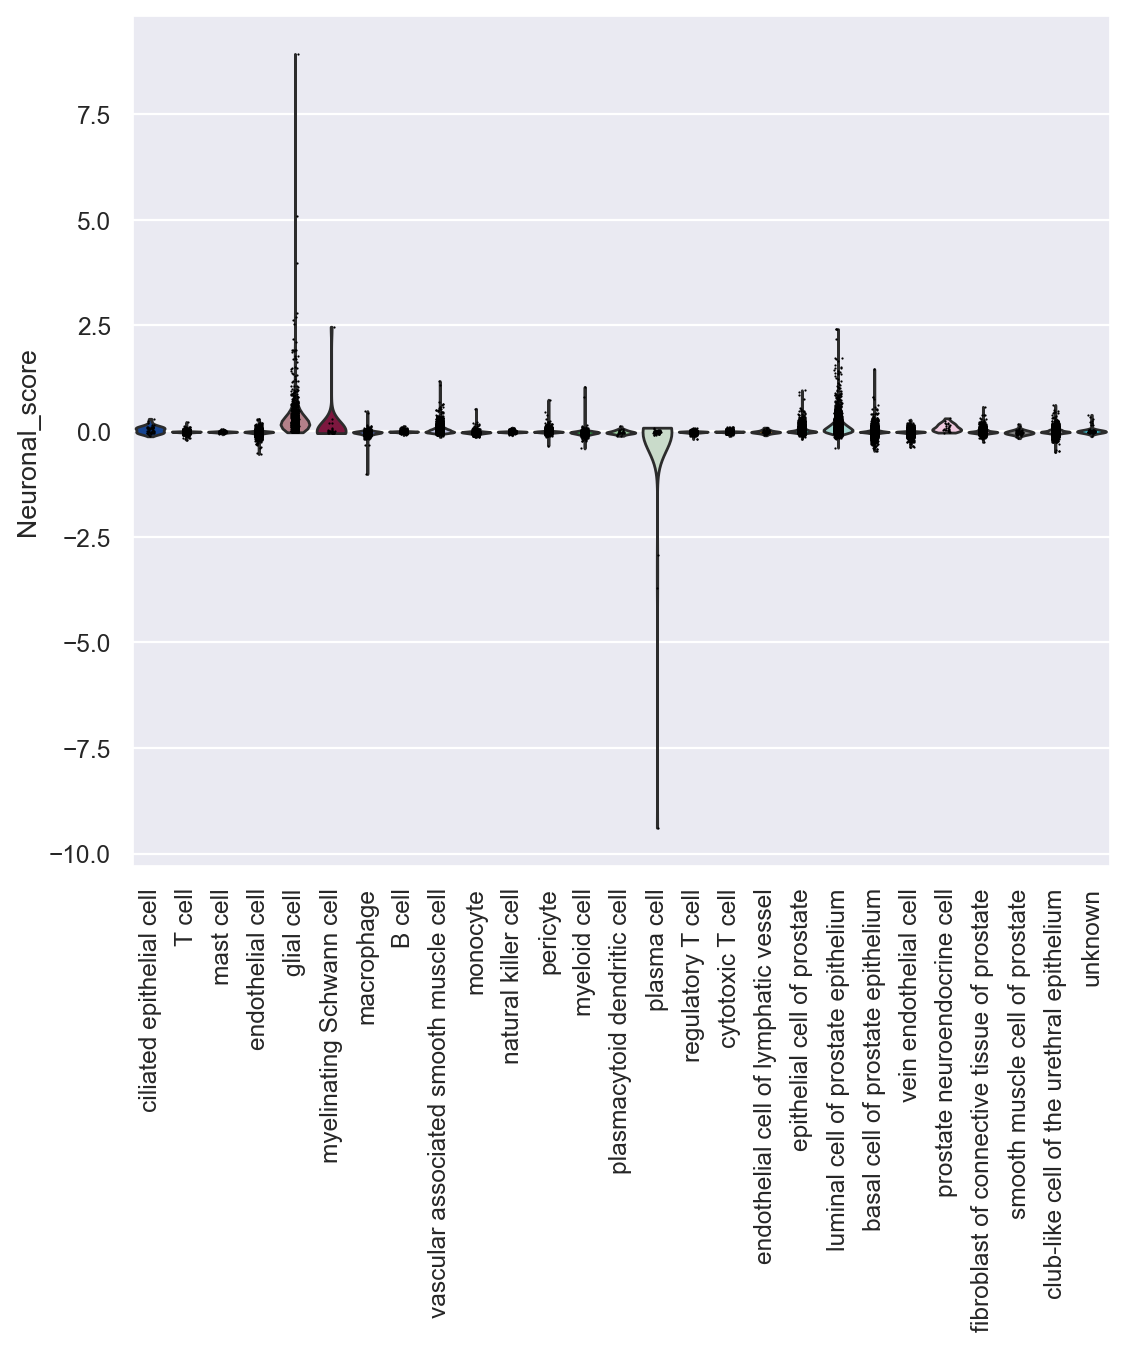

In [87]:
sc.pl.violin(
    adata,
    keys="Neuronal_score",
    groupby="cell_type",
    rotation=90,
)

In [127]:
sns.set_style(style='white')

In [128]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = adata.obs[["cell_type", "Neuronal_score"]].copy()

order = (
    plot_df.groupby("cell_type")["Neuronal_score"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(7, 7))
sns.boxplot(data=plot_df, x="cell_type", y="Neuronal_score", order=order,
                showfliers=False, palette="vlag_r")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("/Users/tobymilne-clark/Documents/Data/Atlas/scRNA_prostate/H5ad/External/plots/Neuronal_score_umap.pdf", bbox_inches="tight", dpi=300)
plt.close()


/var/folders/qx/vj7pdgzn161d8wfjtwfmv7200000gn/T/ipykernel_81034/1492014125.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plot_df.groupby("cell_type")["Neuronal_score"]
/var/folders/qx/vj7pdgzn161d8wfjtwfmv7200000gn/T/ipykernel_81034/1492014125.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="cell_type", y="Neuronal_score", order=order,


In [129]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = adata.obs[["celltype_major_v2", "Neuronal_score"]].copy()

order = (
    plot_df.groupby("celltype_major_v2")["Neuronal_score"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(7, 7))
sns.boxplot(data=plot_df, x="celltype_major_v2", y="Neuronal_score", order=order,
                showfliers=False, palette="vlag_r")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("/Users/tobymilne-clark/Documents/Data/Atlas/scRNA_prostate/H5ad/External/plots/Neuronal_score_broad_umap.pdf", bbox_inches="tight", dpi=300)
plt.close()

/var/folders/qx/vj7pdgzn161d8wfjtwfmv7200000gn/T/ipykernel_81034/2323627382.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plot_df.groupby("celltype_major_v2")["Neuronal_score"]
/var/folders/qx/vj7pdgzn161d8wfjtwfmv7200000gn/T/ipykernel_81034/2323627382.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="celltype_major_v2", y="Neuronal_score", order=order,


In [130]:

# change these to match your object
celltype_col = "cell_type"
grade_col = "ISUP_clinical"
score_col = "Neuronal_score"


plot_df = adata.obs[[celltype_col, grade_col, "Neuronal_score"]].copy()

plot_df = plot_df[
    plot_df[celltype_col].astype(str).str.contains(
        "luminal|basal|club|epithelial|epithelium|neuroendocrine|neuron|glial|schwann",
        case=False,
        na=False
    )
].copy()

plot_df = plot_df.dropna(subset=[celltype_col, grade_col, score_col])
plot_df[grade_col] = plot_df[grade_col].astype(str)

# optional: order epithelial cell types by median score
order = (
    plot_df.groupby(celltype_col)[score_col]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(9, 7))
sns.boxplot(
    data=plot_df,
    x=celltype_col,
    y=score_col,
    hue=grade_col,
    order=order,
    showfliers=False
)

plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(
    "/Users/tobymilne-clark/Documents/Data/Atlas/scRNA_prostate/H5ad/External/plots/Neuronal_score_by_epithelial_celltype_ISUP.pdf",
    bbox_inches="tight",
    dpi=300
)
plt.close()

/var/folders/qx/vj7pdgzn161d8wfjtwfmv7200000gn/T/ipykernel_81034/3546214165.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plot_df.groupby(celltype_col)[score_col]


In [131]:
celltype_col = "cell_type"
grade_col = "ISUP_clinical"
score_col = "Neuronal_score"

plot_df = adata.obs[[celltype_col, grade_col, score_col]].copy()

# keep only luminal cells
plot_df = plot_df[
    plot_df[celltype_col].astype(str).str.contains("luminal", case=False, na=False)
].copy()

plot_df = plot_df.dropna(subset=[grade_col, score_col])

# make grade ordering nicer
plot_df[grade_col] = plot_df[grade_col].astype(str)
grade_order = ["2", "3", "4", "5"]
grade_order = [g for g in grade_order if g in plot_df[grade_col].unique()]

plt.figure(figsize=(7, 7))
sns.boxplot(
    data=plot_df,
    x=grade_col,
    y=score_col,
    order=grade_order if len(grade_order) > 0 else None,
    showfliers=False,
    palette="Set2")

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "/Users/tobymilne-clark/Documents/Data/Atlas/scRNA_prostate/H5ad/External/plots/Neuronal_score_luminal_by_ISUP.pdf",
    bbox_inches="tight",
    dpi=300
)
plt.close()

/var/folders/qx/vj7pdgzn161d8wfjtwfmv7200000gn/T/ipykernel_81034/2301000497.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


In [88]:
rho_genes = ["ARHGAP25", "ARHGAP26", "ARHGEF7", "BAIAP2", "BCR", "EPHA2",   "FAM13A", "FARP1", "ITGB1", "MCF2", "PAK6", "PLEKHG3",   "SRGAP3", "TAOK3", "VAV2", "VAV3"]
mapped = symbols_to_ensembl(rho_genes, adata, symbol_col="gene_name", strip_version=False)
gene_list_ens = [v for v in mapped.values() if v is not None]
gene_list_ens = [g for g in gene_list_ens if g in adata.var_names]

print(gene_list_ens)

sc.tl.score_genes(
    adata,
    gene_list=gene_list_ens,
    score_name="Rho_score"
)

[
    'ENSG00000163219',
    'ENSG00000145819',
    'ENSG00000102606',
    'ENSG00000175866',
    'ENSG00000186716',
    'ENSG00000142627',
    'ENSG00000138640',
    'ENSG00000152767',
    'ENSG00000150093',
    'ENSG00000101977',
    'ENSG00000137843',
    'ENSG00000126822',
    'ENSG00000196220',
    'ENSG00000135090',
    'ENSG00000160293',
    'ENSG00000134215'
]

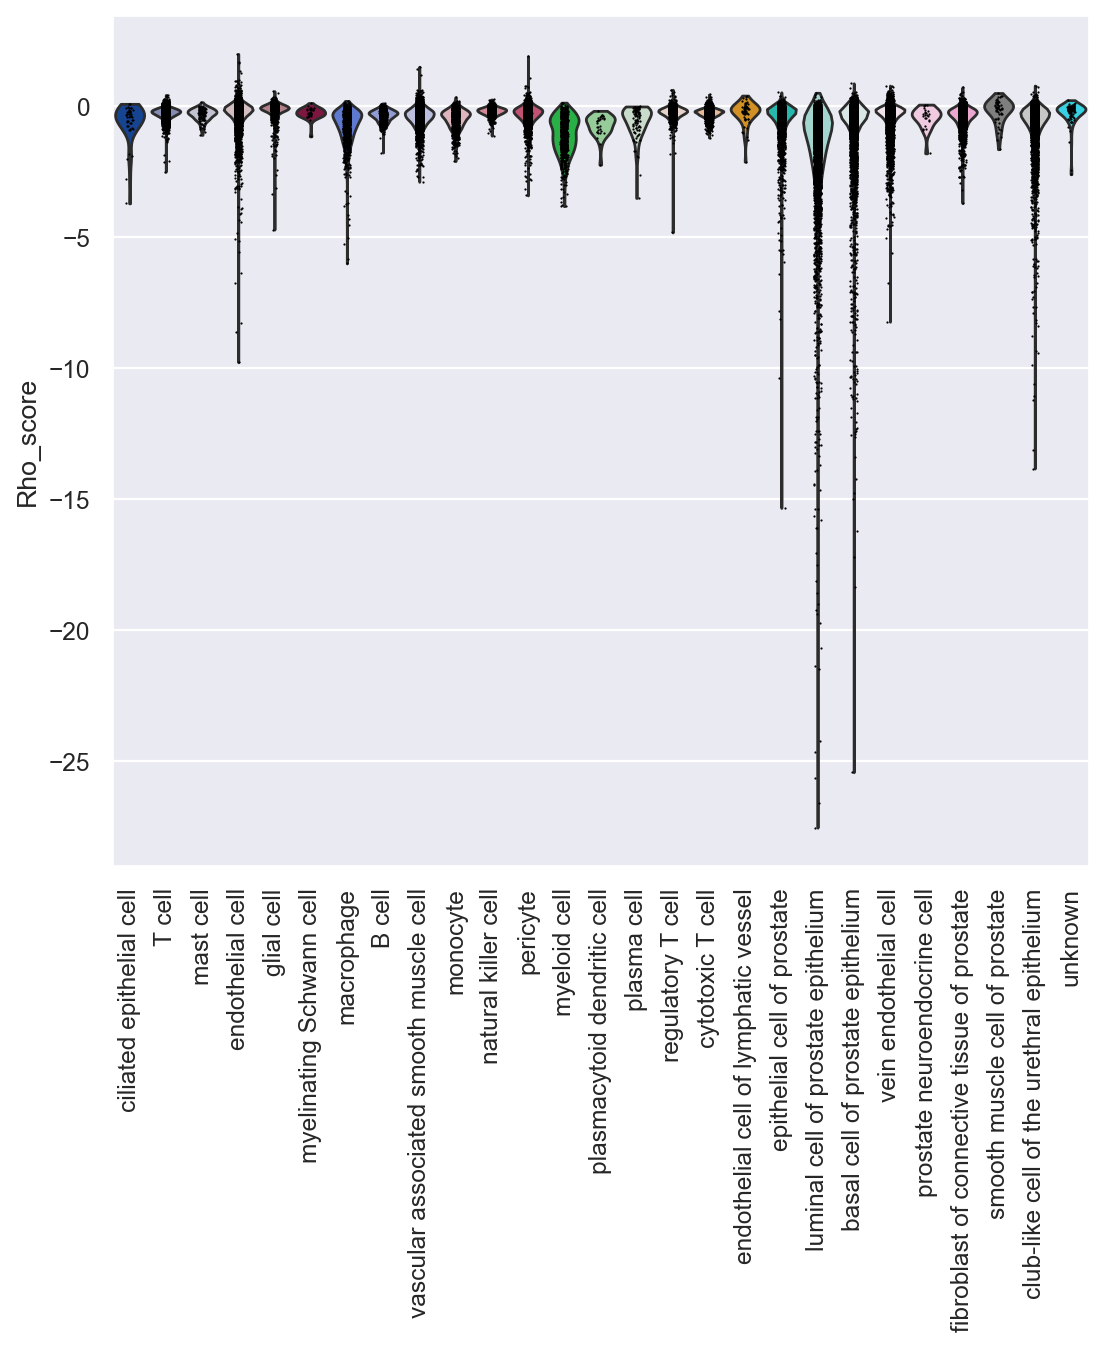

In [89]:
sc.pl.violin(
    adata,
    keys="Rho_score",
    groupby="cell_type",
    rotation=90,
)

In [108]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = adata.obs[["cell_type", "Rho_score"]].copy()

order = (
    plot_df.groupby("cell_type")["Rho_score"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(7, 7))
sns.boxplot(data=plot_df, x="cell_type", y="Rho_score", order=order,
                showfliers=False, palette="vlag_r")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("/Users/tobymilne-clark/Documents/Data/Atlas/scRNA_prostate/H5ad/External/plots/Rho_score_umap.pdf", bbox_inches="tight", dpi=300)
plt.close()

/var/folders/qx/vj7pdgzn161d8wfjtwfmv7200000gn/T/ipykernel_81034/3587115289.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plot_df.groupby("cell_type")["Rho_score"]
/var/folders/qx/vj7pdgzn161d8wfjtwfmv7200000gn/T/ipykernel_81034/3587115289.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="cell_type", y="Rho_score", order=order,


In [ ]:
gene_sets = {
    "cytotoxic_score": ["NKG7", "CCL5", "PRF1", "GZMB", "GNLY"],
    "exhaustion_score": ["PDCD1", "LAG3", "HAVCR2", "TIGIT", "TOX", "CXCL13"],
    "treg_score": ["FOXP3", "IL2RA", "CTLA4", "TIGIT", "IKZF2"],
    "ifn_score": ["ISG15", "IFIT1", "IFIT3", "MX1", "OAS1"],
    "apc_score": ["HLA-DRA", "HLA-DPB1", "CD74", "FCER1A", "CST3"],
    "inflammatory_myeloid_score": ["S100A8", "S100A9", "IL1B", "FCN1", "CTSB"],
    "tam_like_score": ["SPP1", "TREM2", "MRC1", "APOE", "C1QC"]
}

In [106]:
exhaustion_genes = ["PDCD1", "LAG3", "HAVCR2", "TIGIT", "TOX", "CXCL13"]
mapped = symbols_to_ensembl(exhaustion_genes, adata, symbol_col="gene_name", strip_version=False)
gene_list_ens = [v for v in mapped.values() if v is not None]
gene_list_ens = [g for g in gene_list_ens if g in adata.var_names]

print(gene_list_ens)

sc.tl.score_genes(
    adata,
    gene_list=gene_list_ens,
    score_name="exhaustion_score"
)

['ENSG00000188389', 'ENSG00000089692', 'ENSG00000135077', 'ENSG00000181847', 'ENSG00000198846', 'ENSG00000156234']

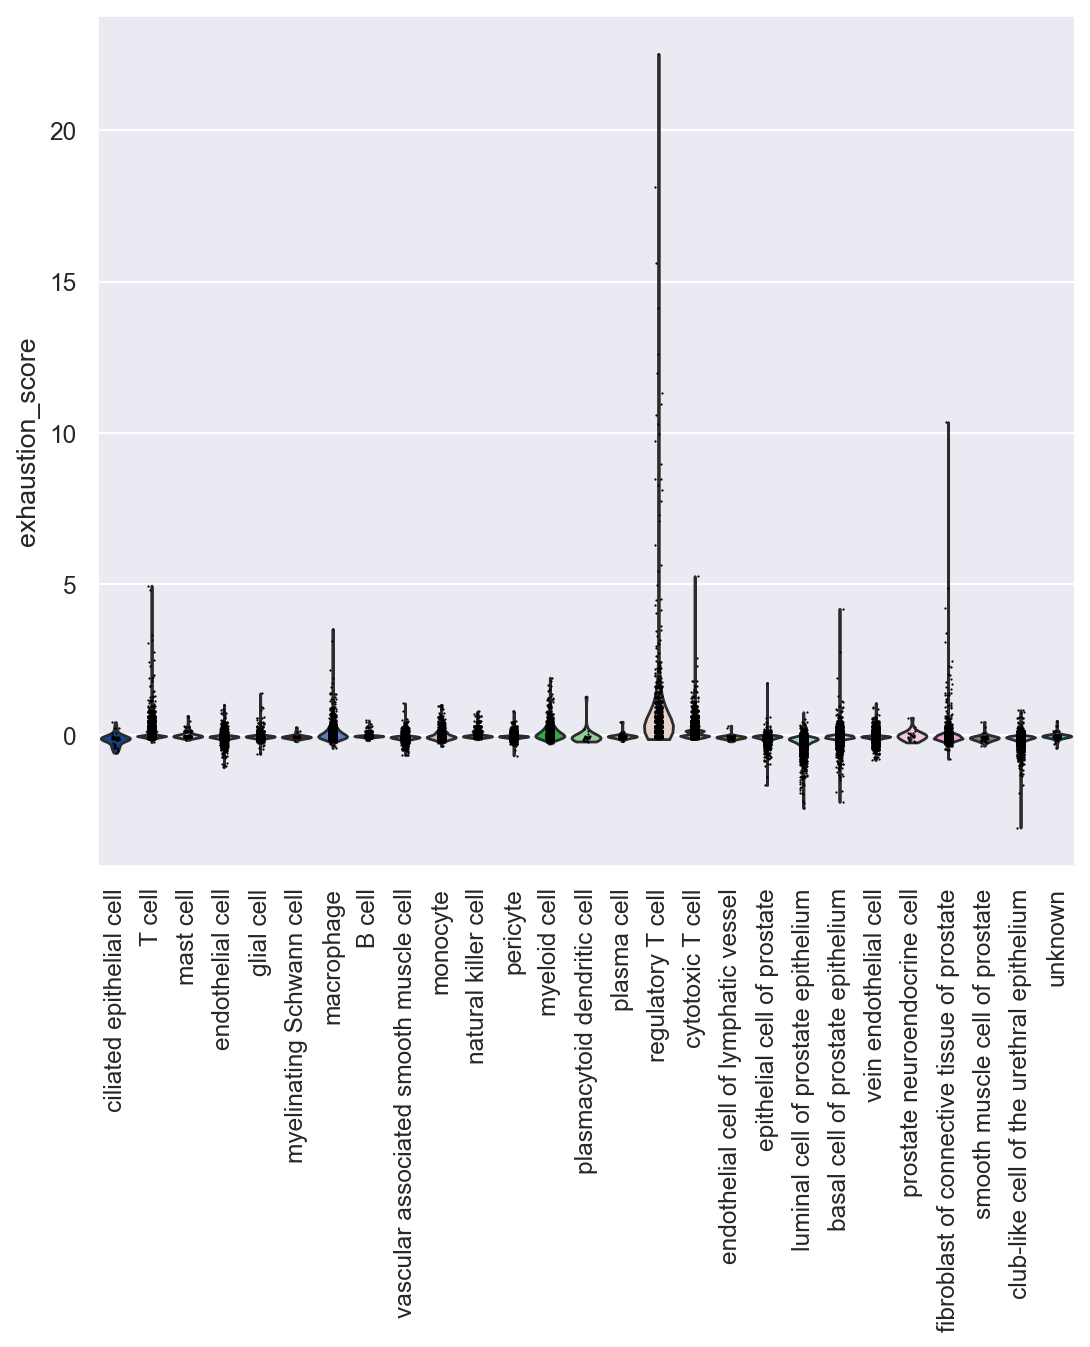

In [107]:
sc.pl.violin(
    adata,
    keys="exhaustion_score",
    groupby="cell_type",
    rotation=90,
)

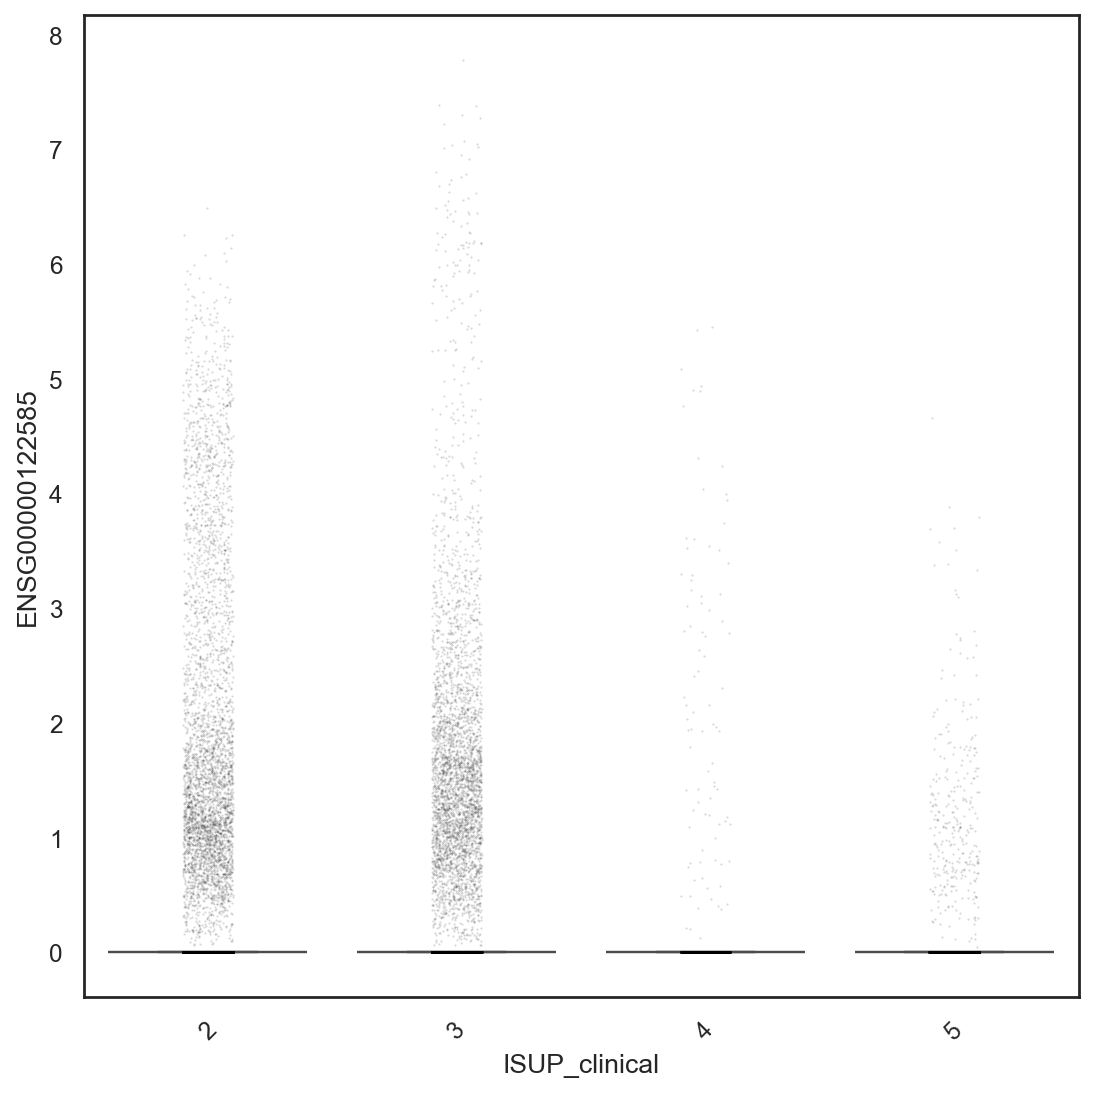

In [135]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.sparse as sp

gene = "ENSG00000122585"
grade_col = "ISUP_clinical"

# extract expression
expr = adata[:, gene].X

if sp.issparse(expr):
    expr = expr.toarray().flatten()
else:
    expr = expr.flatten()

plot_df = adata.obs[[grade_col]].copy()
plot_df["ENSG00000122585"] = expr
plot_df = plot_df.dropna(subset=[grade_col, "ENSG00000122585"])

plt.figure(figsize=(7, 7))
sns.boxplot(data=plot_df, x=grade_col, y="ENSG00000122585", showfliers=False)
sns.stripplot(data=plot_df, x=grade_col, y="ENSG00000122585", color="black", alpha=0.15, size=1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

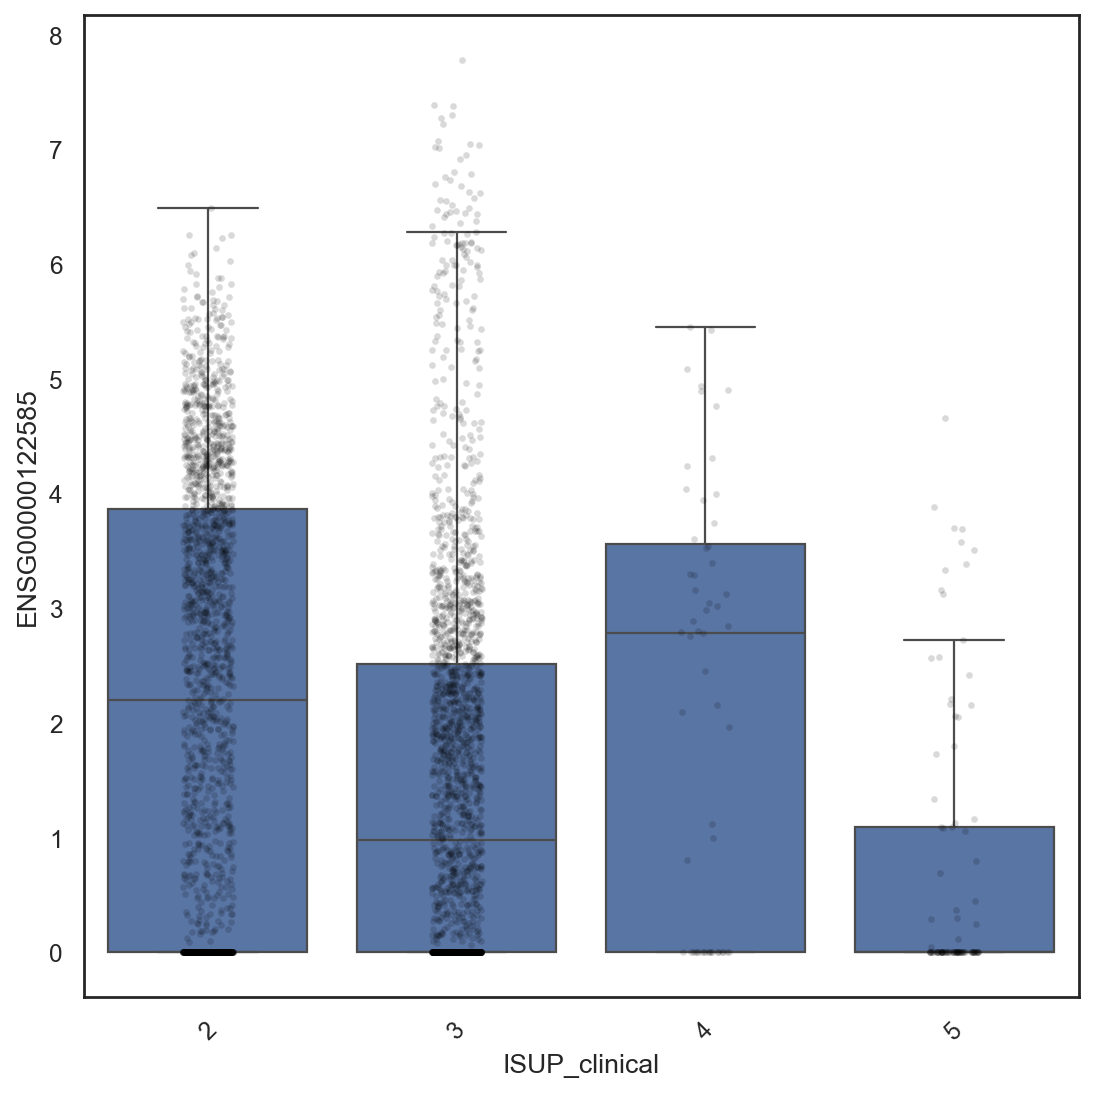

In [137]:
celltype_col = "cell_type"

plot_df = adata.obs[[celltype_col, grade_col]].copy()
plot_df = plot_df[
    plot_df[celltype_col].astype(str).str.contains("luminal", case=False, na=False)
].copy()

expr = adata[plot_df.index, gene].X
if sp.issparse(expr):
    expr = expr.toarray().flatten()
else:
    expr = expr.flatten()

plot_df["ENSG00000122585"] = expr
plot_df = plot_df.dropna(subset=[grade_col, "ENSG00000122585"])

plt.figure(figsize=(7, 7))
sns.boxplot(data=plot_df, x=grade_col, y="ENSG00000122585", showfliers=False)
sns.stripplot(data=plot_df, x=grade_col, y="ENSG00000122585", color="black", alpha=0.15, size=3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/var/folders/qx/vj7pdgzn161d8wfjtwfmv7200000gn/T/ipykernel_81034/1124980894.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plot_df.groupby(celltype_col)["NPY"]


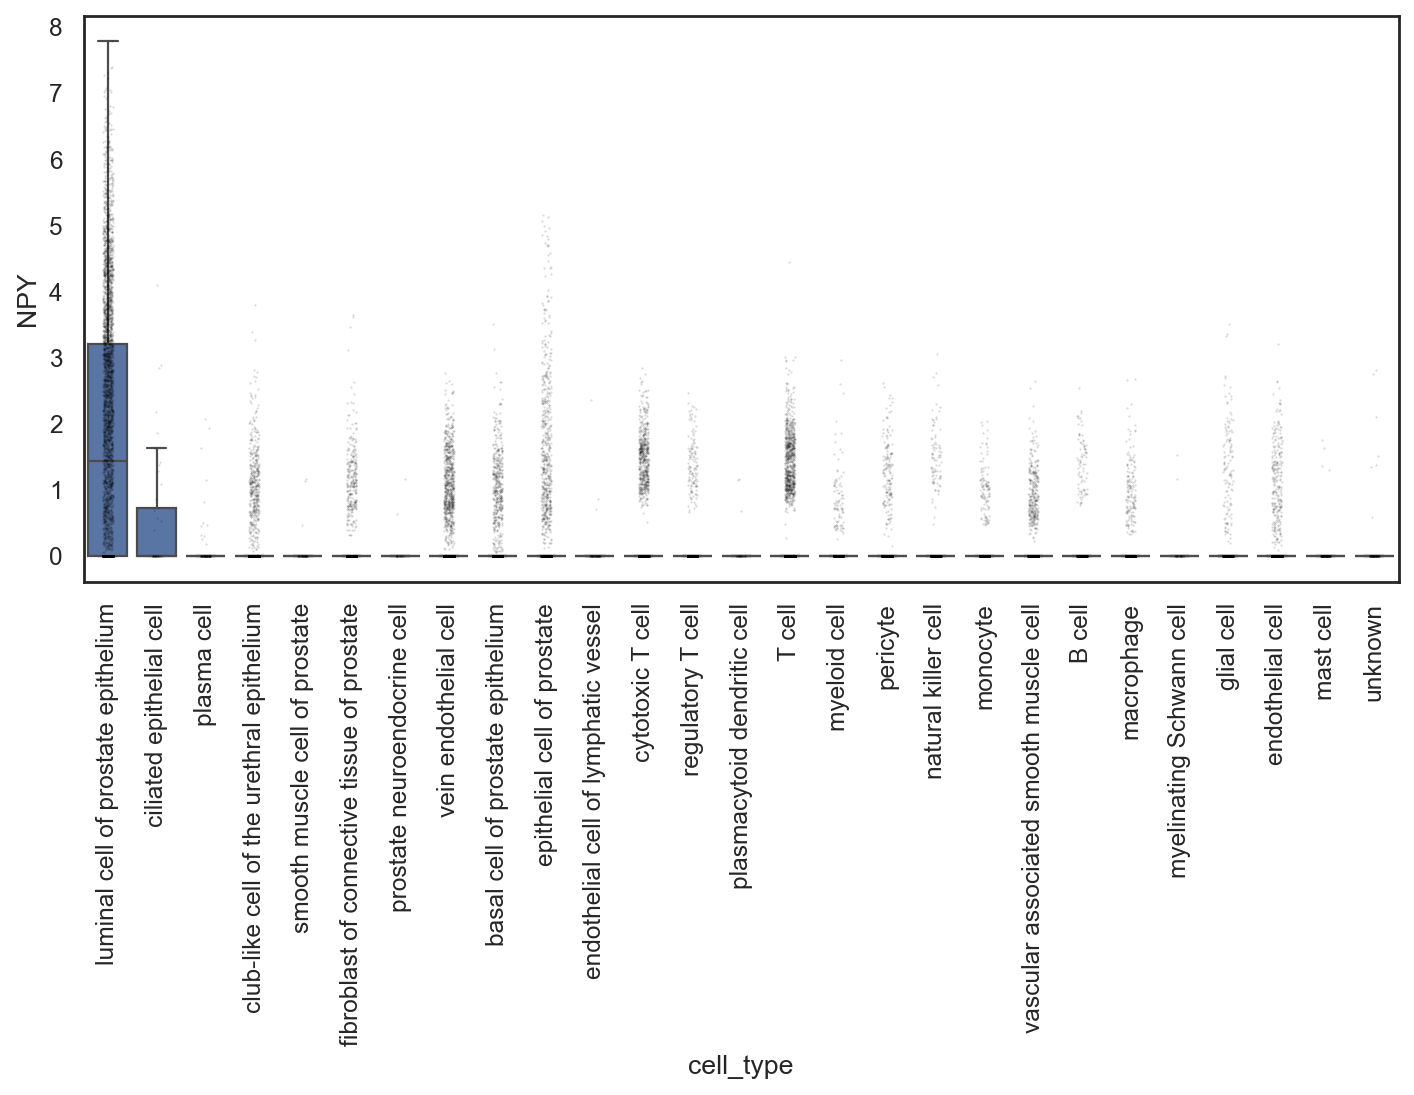

In [139]:
import scipy.sparse as sp
import seaborn as sns
import matplotlib.pyplot as plt

gene = "ENSG00000122585"
celltype_col = "cell_type"

expr = adata[:, gene].X
expr = expr.toarray().flatten() if sp.issparse(expr) else expr.flatten()

plot_df = adata.obs[[celltype_col]].copy()
plot_df["NPY"] = expr
plot_df = plot_df.dropna(subset=[celltype_col, "NPY"])

order = (
    plot_df.groupby(celltype_col)["NPY"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(9, 7))
sns.boxplot(
    data=plot_df,
    x=celltype_col,
    y="NPY",
    order=order,
    showfliers=False
)
sns.stripplot(
    data=plot_df,
    x=celltype_col,
    y="NPY",
    order=order,
    color="black",
    alpha=0.15,
    size=1
)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()